# A small analysis

This notebook is MD Buddy's example for **Jupyter notebook previews**. Every output below was
produced by running the notebook (`scripts/make_example_notebook.py`).

The sample mean is $\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$, and prices like $5 and $10 are
left alone. A display equation:

$$
\hat{\beta} = (X^\top X)^{-1} X^\top y
$$

Jupyter also typesets a LaTeX environment written without dollar signs:

\begin{align}
y_i &= \beta_0 + \beta_1 x_i + \varepsilon_i \\
\varepsilon_i &\sim \mathcal{N}(0, \sigma^2)
\end{align}

| Cell type | Shown as |
|:--|:--|
| Markdown | formatted text |
| Code | highlighted source and its outputs |


## An attached image

Images pasted into a cell are stored inside the notebook: 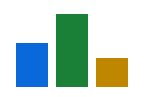


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
x = np.linspace(0, 10, 60)
y = 1.5 + 0.8 * x + rng.normal(0, 1.2, x.size)
df = pd.DataFrame({"x": x, "y": y, "group": np.where(x < 5, "low", "high")})
print(f"{len(df)} observations")

60 observations


In [2]:
df.head()

,x,y,group
0,0.000000,1.501476,low
1,0.169492,1.994088,low
2,0.338983,1.442221,low
3,0.508475,0.838069,low
4,0.677966,1.496768,low


In [3]:
summary = df.groupby("group")[["x", "y"]].agg(["mean", "std"]).round(2)
summary.style.background_gradient(cmap="Blues").format("{:.2f}")

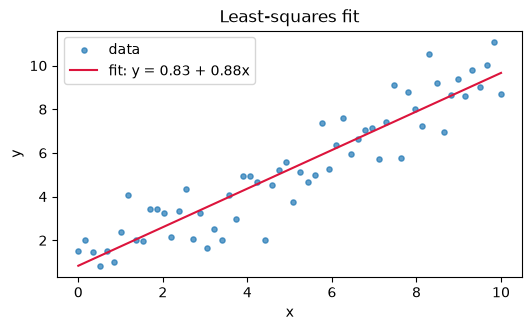

In [4]:
slope, intercept = np.polyfit(df.x, df.y, 1)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.scatter(df.x, df.y, s=14, alpha=0.7, label="data")
ax.plot(df.x, intercept + slope * df.x, color="crimson", label=f"fit: y = {intercept:.2f} + {slope:.2f}x")
ax.set(xlabel="x", ylabel="y", title="Least-squares fit")
ax.legend()
plt.show()

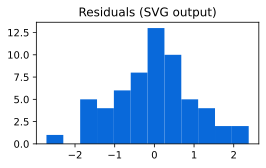

In [5]:
%config InlineBackend.figure_formats = ['svg']
fig, ax = plt.subplots(figsize=(4, 2.2))
ax.hist(df.y - (intercept + slope * df.x), bins=12, color="#0969da")
ax.set_title("Residuals (SVG output)")
plt.show()
%config InlineBackend.figure_formats = ['png']

In [6]:
print("written to stdout")
print("a warning written to stderr", file=sys.stderr)

written to stdout


a warning written to stderr


In [7]:
from IPython.display import JSON, Markdown, Math, display

display(Markdown(f"The fitted slope is **{slope:.3f}**, so $\\hat{{y}} = {intercept:.2f} + {slope:.2f}x$."))
display(Math(r"R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}"))
display({"application/json": {"slope": round(float(slope), 3), "intercept": round(float(intercept), 3), "n": len(df)}}, raw=True)

The fitted slope is **0.883**, so $\hat{y} = 0.83 + 0.88x$.

<IPython.core.display.Math object>

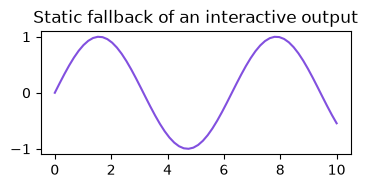

In [8]:
import base64, io

buffer = io.BytesIO()
fig, ax = plt.subplots(figsize=(4, 1.6))
ax.plot(df.x, np.sin(df.x), color="#8250df")
ax.set_title("Static fallback of an interactive output")
fig.savefig(buffer, format="png", bbox_inches="tight")
plt.close(fig)

# What an interactive plotting library emits: HTML that draws only if its script runs,
# plus a static image for viewers that cannot run scripts.
display({
    "text/html": '<div id="interactive-plot"></div><script>drawInteractivePlot("interactive-plot")</script>',
    "image/png": base64.b64encode(buffer.getvalue()).decode("ascii"),
}, raw=True)

In [9]:
def fit(values):
    return np.polyfit(values, df.y, 1)

fit(df.x[:10])  # ten x values against sixty y values

TypeError: expected x and y to have same length